# LGD, recuperaciones y EAD: comparar componentes
## Resumen
Se ajustan LGD por segmento y logit fraccional con casos cerrados, y CCF fraccional con ventanas completas. La LGD por flujos es una alternativa estructural con parámetros suministrados. En 432 workouts reservados, RMSE fue 0,17785 para media segmentada y 0,10335 para logit fraccional. En 390 ventanas CCF, el RMSE pasó de 0,12656 con CCF fijo a 0,09012 con el ajustado. Se compara su comportamiento sin confundir una hipótesis de recuperación con un modelo calibrado.

## Contexto y métodos
LGD de workout es un objetivo continuo en [0,1]. Logit fraccional minimiza cuasiverosimilitud Bernoulli regularizada; admite objetivos exactamente 0 y 1. EAD se mide al inicio del mes de default. En amortizables, $EAD_m=B^{contr}_{m-1}(1-CPR)^{(m-1)/12}$; presupone independencia del prepago respecto del default. En revolventes, $EAD=B+CCF(L-B)$.

### Supuestos
Moneda arbitraria, tasas anuales efectivas, exposición sin sobreutilización ni intereses adicionales al default. CCF se restringe a [0,1]. Recuperaciones y macros son sintéticas; no hay cohortes abiertas ni sesgo de cierre corregido. El target LGD ya está descontado a default; el motor ECL descuenta después de default a reporte.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
ROOT = Path.cwd() if (Path.cwd()/"src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
from src.multimodel import *
from src.multimodel.experiment import fit_experiment
from src.multimodel.validation import binary_metrics, bootstrap_mean_interval
plt.rcParams.update({"figure.figsize": (9, 4.5), "font.size": 11, "axes.spines.top": False, "axes.spines.right": False})
COLORS = ["#245B78", "#BE672F", "#398168"]
ex = fit_experiment()


## Datos: entrenamiento y ventanas reservadas
LGD y CCF se entrenan sólo con `completion_month < 30`. Los casos posteriores se reservan para diagnóstico. El panel de workouts es independiente del de PD; no permite estimar dependencia residual LGD–EAD.

In [2]:
w=ex["workouts"].query("completion_month >= 30").copy()
c=ex["windows"].query("completion_month >= 30").copy()
rows=[]
for model in ex["lgd_models"][:2]:
    pred=(model.predict(w,[0.],np.ones((len(w),1)))[:,0] if model.model_id=="lgd_segment_workout"
          else model.regression.predict(w[["collateral_ratio","segment","macro"]]))
    rows.append({"modelo":model.model_id,"casos":len(w),"MAE":np.abs(pred-w.loss_fraction).mean(),"RMSE":np.mean((pred-w.loss_fraction)**2)**.5,"sesgo":np.mean(pred-w.loss_fraction)})
display(pd.DataFrame(rows).round(5))

,modelo,casos,MAE,RMSE,sesgo
0,lgd_segment_workout,432,0.14569,0.17785,0.00964
1,lgd_fractional_workout,432,0.08336,0.10335,-0.00193


## Resultados: severidad y garantías

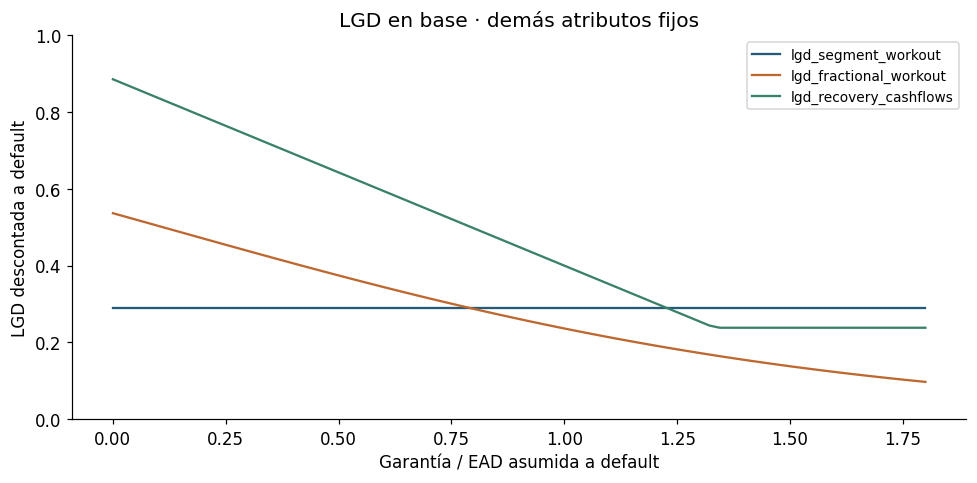

In [3]:
grid=ex["loans"].iloc[:1].copy().loc[lambda x:x.index.repeat(80)].reset_index(drop=True)
grid["collateral_ratio"]=np.linspace(0,1.8,len(grid));grid["eir"]=.12
fig,ax=plt.subplots()
for model,color in zip(ex["lgd_models"],COLORS):
    pred=model.predict(grid,[0.],np.ones((len(grid),1)))[:,0]
    ax.plot(grid.collateral_ratio,pred,color=color,label=model.model_id)
ax.set(title="LGD en base · demás atributos fijos",xlabel="Garantía / EAD asumida a default",ylabel="LGD descontada a default",ylim=(0,1))
ax.legend(fontsize=9);fig.tight_layout();plt.show()

El promedio por segmento no responde a garantía individual; la regresión sí. La curva por flujos usa haircut, costos y recuperación no garantizada supuestos. Las diferencias de nivel no prueban cuál es más correcto.

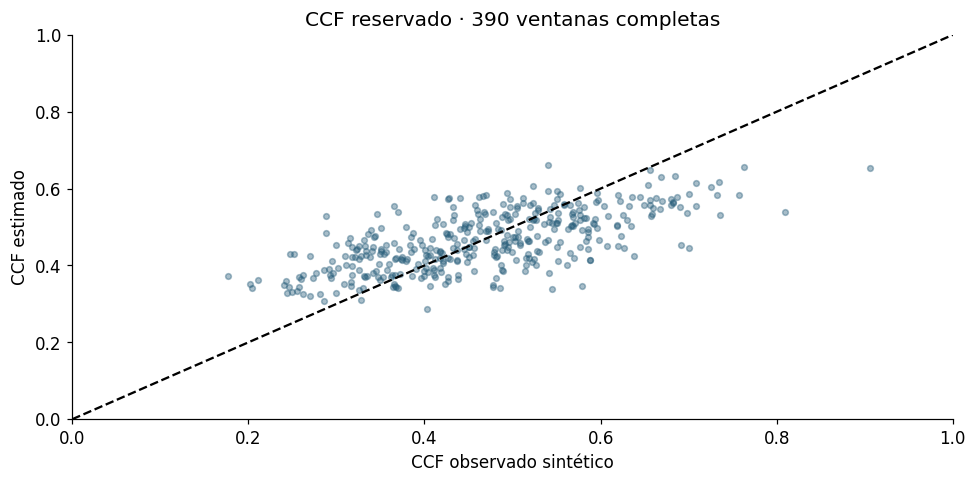

,modelo,MAE,RMSE,sesgo
0,CCF fijo 0.5,0.10307,0.12656,0.03378
1,CCF fraccional,0.07315,0.09012,-0.00146


In [4]:
model=ex["ead_models"][1].ccf_model
pred=model.predict(c.utilization,c.segment,c.macro)
ccf_metrics=pd.DataFrame([{"modelo":name,"MAE":np.abs(p-c.ccf).mean(),"RMSE":np.mean((p-c.ccf)**2)**.5,"sesgo":np.mean(p-c.ccf)} for name,p in [("CCF fijo 0.5",np.full(len(c),.5)),("CCF fraccional",pred)]])
display(ccf_metrics.round(5))
fig,ax=plt.subplots()
ax.scatter(c.ccf,pred,s=14,alpha=.4,color=COLORS[0]);ax.plot([0,1],[0,1],"k--")
ax.set(title=f"CCF reservado · {len(c)} ventanas completas",xlabel="CCF observado sintético",ylabel="CCF estimado",xlim=(0,1),ylim=(0,1));fig.tight_layout();plt.show()

### Amortización y prepago
Se grafican saldos desde información al corte. No se usan saldos futuros observados como predictores.

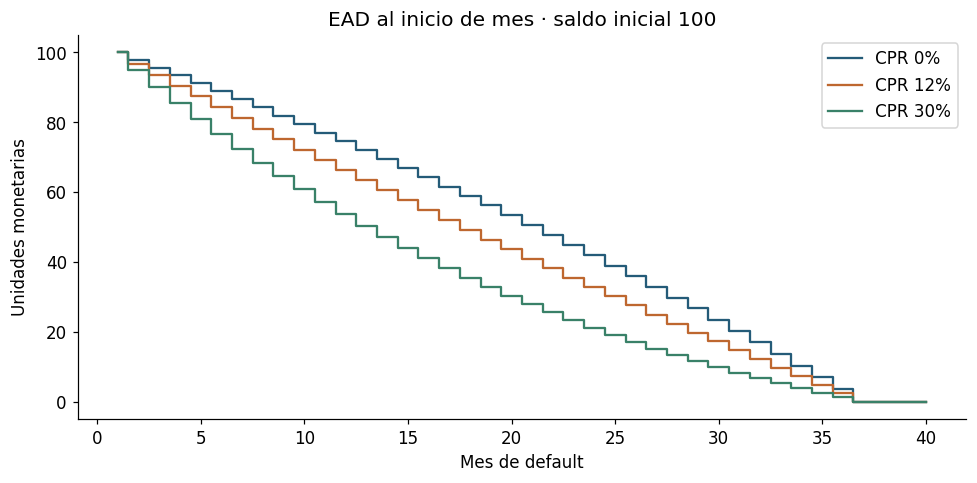

In [5]:
fig,ax=plt.subplots()
for cpr,color in zip([0,.12,.30],COLORS):
    trajectory=annuity_exposure(100,.18,36,40,cpr)
    ax.step(np.arange(1,41),trajectory,where="mid",color=color,label=f"CPR {cpr:.0%}")
ax.set(title="EAD al inicio de mes · saldo inicial 100",xlabel="Mes de default",ylabel="Unidades monetarias")
ax.legend();fig.tight_layout();plt.show()
a=annuity_exposure(120,0,3,5);np.testing.assert_allclose(a,[120,80,40,0,0])

### Recuperar el mismo monto más tarde aumenta la pérdida
El calendario de recuperación se descuenta una vez a default. Para Stage 3, la recuperación se descuenta directamente a reporte.

In [6]:
loan=ex["loans"].iloc[[0]].copy();loan["eir"]=.12
rows=[]
for delay in [0,1,2,3]:
    m=CashflowLGD(recovery_years=tuple(np.array([1.,2.,3.])+delay))
    rows.append({"demora_adicional_años":delay,"LGD":m.predict(loan,[0.],np.ones((1,1)))[0,0]})
display(pd.DataFrame(rows).round(5))
assert np.all(np.diff([r["LGD"] for r in rows])>0)

,demora_adicional_años,LGD
0,0,0.59981
1,1,0.64269
2,2,0.68097
3,3,0.71515


## Conclusiones y límites
El benchmark distingue ajuste estadístico de supuestos de flujo. Los errores de CCF no equivalen a errores monetarios de EAD: éstos dependen del cupo no utilizado. La validación con recuperaciones abiertas, sobreutilización, cambios de límite y prepago dependiente del riesgo requiere modelos adicionales. El descuento de LGD y el descuento de ECL representan intervalos distintos, evitando doble descuento del mismo período.